# 가설 2 (수정안) — 맥락 모델은 글의 내용이 아니라 "새로 쓴 티"에 반응하고 있다

**진짜 궁금한 것**: Context+Comment 모델이 게시글 **내용과 댓글의 관계**를 읽는가, 아니면 게시글의 **겉모습**(사람이 새로 쓴 티)만 보는가?

**왜 의심하나**
KOCOH의 Type 1과 Type 2는 **같은 댓글**에 서로 다른 게시글(Context)이 붙은 쌍이다.
Type 2의 Context는 원래 게시글을 사람이 비혐오로 읽히도록 고쳐 쓴 문장이고, Type 2는 전부 비혐오다.
그래서 모델이 댓글과의 관계를 읽지 않고 "고쳐 쓴 글처럼 보이면 비혐오, 실제 글처럼 보이면 혐오"라고만 판단해도 점수가 오른다.

**어떻게 확인하나 — Context 바꿔 끼우기 시험**
가설 1·중간보고와 같은 Context+Comment 모델을 fold마다 학습한 뒤, **댓글은 그대로 두고 test의 Context만 바꿔서** 혐오 확률이 어떻게 변하는지 본다.

| test 입력 | Context | 댓글과의 관계 | 겉모습 |
|---|---|---|---|
| `own` (원래) | 그 댓글의 원래 게시글 | 있음 | 원래 그대로 |
| `real_other` | **다른** 게시글 묶음의 **실제** 게시글 (Type 1·3) | 없음 | 실제 글 |
| `rew_other` | **다른** 게시글 묶음의 **고쳐 쓴** 게시글 (Type 2) | 없음 | 고쳐 쓴 글 |

- **겉모습 효과** = P(혐오 | `real_other`) − P(혐오 | `rew_other`)
  두 입력 모두 댓글과 무관한 글이고 **겉모습만 다르다**. 이 차이가 크면 모델이 겉모습에 반응한다는 뜻이다.
- **내용 효과** = 원래 게시글을, 겉모습은 같고 내용만 무관한 게시글로 바꿨을 때 예측이 **정답 쪽으로 얼마나 덜 가는가**
  Type 1(혐오): P(혐오 | `own`) − P(혐오 | `real_other`) · Type 2(비혐오): P(혐오 | `rew_other`) − P(혐오 | `own`)
  이 값이 크면 모델이 내용과 댓글의 관계를 쓴다는 뜻이다.

**판정 기준 (결과를 보기 전에 정함)** — Type 1·2 행 기준, fold별 값 5개에 중간보고 2-6절 규칙 적용
- 겉모습 효과만 유의 → **가설 지지** (겉모습에 반응)
- 내용 효과만 유의 → **가설 기각** (내용을 읽음)
- 둘 다 유의 → **부분 지지** (둘 다 쓰며, 크기를 비교해 적는다)
- 둘 다 유의하지 않음 → **판단 보류**

| 항목 | 내용 |
|---|---|
| 데이터 | `data/KOCOH_v.2.csv` (3,000행) |
| 분할 | `src/preprocess.py` 의 `cv_splits()` — post_group 단위 StratifiedGroupKFold 5-fold, `Hate speech` 기준 stratify, seed 42 |
| 모델 | Context+Comment 조건만: KcELECTRA-base-v2022 fine-tuning (`src/plm.py` 와 같은 설정), 참고로 TF-IDF + LogReg |
| 바꿔 끼울 Context | 같은 test fold 안에서, **다른 post_group** 의 Context 중 무작위 (3번 뽑아 평균, seed 42) |
| 결과 파일 | `figures/project_h2_style_vs_content.png`, `figures/project_h2_af_hate_rate.png` (예측·효과 표는 파일로 저장하지 않고 노트북 안에서만 계산) |

In [1]:
import os
import sys
from pathlib import Path

os.environ.setdefault('HF_HUB_OFFLINE', '1')        # model/ 에 받아 둔 파일만 사용
os.environ.setdefault('TRANSFORMERS_OFFLINE', '1')
os.environ.setdefault('TOKENIZERS_PARALLELISM', 'false')

import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedGroupKFold

PROJECT_ROOT = Path('..').resolve()
if not (PROJECT_ROOT / 'data').exists():
    PROJECT_ROOT = Path('.').resolve()  # repo 루트에서 실행하는 경우
sys.path.insert(0, str(PROJECT_ROOT / 'src'))

import preprocess as pp
import baseline as bl

SEED = pp.SEED
np.random.seed(SEED)
pd.set_option('display.width', 200)
print(f"seed = {SEED}")
print(f"데이터 경로: {pp.DATA_PATH.relative_to(PROJECT_ROOT)}")

FIG_PATH = PROJECT_ROOT / 'figures' / 'project_h2_style_vs_content.png'

PLM_MODELS = ['KcELECTRA-base-v2022']   # klue-roberta-base 도 보려면 추가 (fold당 학습 1회 더, 약 4~8분)
N_DRAWS = 3                             # 바꿔 끼울 Context 를 몇 번 뽑아 평균할지
VARIANTS = ['own', 'real_other', 'rew_other']

seed = 42
데이터 경로: data/KOCOH_v.2.csv


---
## 1. 설계 점검 — "새로 쓴 티"는 실제로 있는가 (모델 학습 전)

### 1-1. 원래 게시글과 고쳐 쓴 게시글 예시
같은 Set에서 같은 댓글이 붙은 Type 1(실제)·Type 2(고쳐 씀) Context를 나란히 본다.

In [2]:
raw = pd.read_csv(pp.DATA_PATH)
raw = raw.assign(post_group=pp.make_post_groups(raw))
print(f"원본: {len(raw)}행 (결측 행 제거 없음 — Type·Context 결측 {int(raw[['Type', 'Context']].isna().sum().sum())}개)")

pairs = (raw[raw['Type'] == 1][['Set', 'Comment', 'Context']]
         .merge(raw[raw['Type'] == 2][['Set', 'Comment', 'Context']], on=['Set', 'Comment'], suffixes=(' (Type 1, 실제)', ' (Type 2, 고쳐 씀)'))
         .drop_duplicates(subset=['Set', 'Context (Type 1, 실제)', 'Context (Type 2, 고쳐 씀)']))
print(f"같은 Set·같은 댓글로 짝지어지는 서로 다른 (실제, 고쳐 씀) Context 쌍: {len(pairs)}개 — 그중 Set별 1개씩 예시 8개")
display(pairs.groupby('Set').head(1).head(8)[['Set', 'Context (Type 1, 실제)', 'Context (Type 2, 고쳐 씀)']].reset_index(drop=True))

원본: 3000행 (결측 행 제거 없음 — Type·Context 결측 0개)
같은 Set·같은 댓글로 짝지어지는 서로 다른 (실제, 고쳐 씀) Context 쌍: 202개 — 그중 Set별 1개씩 예시 8개


,Set,"Context (Type 1, 실제)","Context (Type 2, 고쳐 씀)"
0,1,여성 고용이 미흡해 정부가 불이익을 준 기업의 이름이 공개되었다.,직원에게 높은 수준의 복지를 제공한 기업의 이름이 공개되었다.
1,2,난임 부부 시술비 지원 시 여성 나이 기준이 폐지되었다.,드라마 이상한 변호사 우영우의 시청률이 높다.
2,3,중국에서 만들어진 사진 변환 인공 지능이 흑인을 제대로 인식하지 못해 사람이 아닌 ...,중국의 새로운 인공 지능 모델이 원숭이가 나오는 재미있는 사진들을 생성했다.
3,4,밀양 성폭행 사건 가해자들이 현재 딸을 낳고 TV에 출연하는 등 잘 살고 있다.,TV 프로그램에 경상남도 밀양시의 돼지 통구이 맛집이 소개되었다.
4,5,독일의 아우슈비츠 수용소가 유대인을 어떻게 죽였는지 설명했다.,그동안 맛집이 없다고 평가받던 독일에서 세계적으로 인기 있는 식당이 등장했다.
5,6,61세 여성 셰인바움이 멕시코 역사상 첫 여성 대통령으로 당선될 가능성이 높다.,암탉과 수탉이 닭장 앞에 모여 모이를 먹고 있다.
6,7,글쓴이가 전과 14범인 전라도 조폭 출신 타 업체 대표가 자신의 남편을 폭행한 사연...,전국에서 가장 맛있는 한정식집이 어디 있는지 물었다.
7,8,미국 교수가 남녀 임금 격차는 존재하지 않는다고 주장했다.,미국 교수가 현대 사회는 전대미문의 자유를 누리고 있다고 주장했다.


### 1-2. Context만 보고 "고쳐 쓴 글"을 가려낼 수 있는가

고유 Context 문장마다 정답을 "고쳐 씀(Type 2) / 실제(Type 1·3)"로 두고, **Context만** 보는 분류기를 post_group 단위 5-fold로 평가한다.
- 잘 가려낸다면 모델이 쓸 수 있는 겉모습 단서가 **존재한다**는 뜻이다 (필요조건). 실제로 모델이 그 단서를 쓰는지는 2절에서 본다.
- 글자 수만 쓴 분류기도 함께 본다 (Type 2 Context가 평균적으로 더 짧다).

In [3]:
ctx = (raw.groupby('Context')
          .agg(rewritten=('Type', lambda t: int((t == 2).all())), mixed=('Type', lambda t: (t == 2).any() and not (t == 2).all()),
               post_group=('post_group', 'first'))
          .reset_index())
print(f"고유 Context {len(ctx)}개 (고쳐 씀 {ctx['rewritten'].sum()} / 실제 {len(ctx) - ctx['rewritten'].sum()}), "
      f"Type 2와 실제 행에 함께 나오는 Context {int(ctx['mixed'].sum())}개는 '실제'로 둠")

length = pd.DataFrame({'Context 글자 수 평균': raw.assign(L=raw['Context'].str.len()).groupby('Type')['L'].mean().round(1),
                       '고유 Context 수': raw.groupby('Type')['Context'].nunique()})
length.index = [f"Type {t}" for t in length.index]
display(length)

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
det_rows = []
for fold, (tr, te) in enumerate(sgkf.split(ctx, ctx['rewritten'], ctx['post_group'])):
    a, b = ctx.iloc[tr], ctx.iloc[te]
    vec = bl.make_tfidf().fit(a['Context'])
    clf = bl.make_logreg().fit(vec.transform(a['Context']), a['rewritten'])
    p_txt = clf.predict(vec.transform(b['Context']))
    L = lambda d: d['Context'].str.len().to_numpy().reshape(-1, 1)
    p_len = LogisticRegression(class_weight='balanced').fit(L(a), a['rewritten']).predict(L(b))
    for name, p in [('TF-IDF (Context만)', p_txt), ('글자 수만', p_len)]:
        det_rows.append({'분류기': name, 'fold': fold, 'macro_f1': f1_score(b['rewritten'], p, average='macro'),
                         'accuracy': accuracy_score(b['rewritten'], p)})
det = pd.DataFrame(det_rows)
print("[고쳐 쓴 Context 판별 — post_group 5-fold 평균 ± 표준편차, 바닥선(찍기) macro-F1 ≈ 0.5]")
display(det.groupby('분류기', sort=False)[['macro_f1', 'accuracy']].agg(bl.mean_std))

# 어떤 표현이 '고쳐 쓴 티'인가 (설명용: 고유 Context 전체로 한 번 학습한 가중치 상위)
vec = bl.make_tfidf().fit(ctx['Context'])
clf = bl.make_logreg().fit(vec.transform(ctx['Context']), ctx['rewritten'])
w = pd.Series(clf.coef_[0], index=vec.get_feature_names_out()).sort_values()
print("가중치 상위 글자 n-gram (설명용, 평가 아님)")
display(pd.DataFrame({'실제 글 쪽': w.head(15).index, '고쳐 쓴 글 쪽': w.tail(15).index[::-1]}))

고유 Context 282개 (고쳐 씀 171 / 실제 111), Type 2와 실제 행에 함께 나오는 Context 1개는 '실제'로 둠


,Context 글자 수 평균,고유 Context 수
Type 1,54.8,110
Type 2,43.3,172
Type 3,50.7,90


[고쳐 쓴 Context 판별 — post_group 5-fold 평균 ± 표준편차, 바닥선(찍기) macro-F1 ≈ 0.5]


,macro_f1,accuracy
분류기,,
TF-IDF (Context만),0.705 ± 0.098,0.732 ± 0.076
글자 수만,0.673 ± 0.103,0.683 ± 0.101


가중치 상위 글자 n-gram (설명용, 평가 아님)


,실제 글 쪽,고쳐 쓴 글 쪽
0,여성,맛
1,여성,있
2,여,오
3,남,있다
4,성이,있다
5,성이,물
6,여성이,올
7,여성이,지
8,여성이,물었다
9,대,물었다.


---
## 2. Context 바꿔 끼우기 시험

fold마다
1. train으로 Context+Comment 모델을 학습한다 (중간보고와 같은 코드·설정·seed).
2. test를 세 가지로 만든다: `own`(원래), `real_other`, `rew_other`. 바꿔 끼울 Context는 **같은 test fold 안, 다른 post_group** 에서만 고른다 → train에서 본 문장은 쓰지 않고, 우연히 같은 게시글이 들어가지도 않는다.
3. 각 test 행의 혐오 확률 P(혐오)를 저장한다.

- TF-IDF + LogReg 는 Context와 댓글 특성을 **더하기만** 하는 모델이라 원리적으로 둘의 관계를 읽을 수 없다. "관계를 못 읽는 모델이면 어떻게 나오는지"를 보여주는 참고선이다.
- 예측은 파일로 저장하지 않고 메모리에만 둔다. 그래서 노트북을 다시 실행하면 **처음부터 다시 학습**한다.
- 학습 시간: KcELECTRA fine-tuning 1회 약 4~8분 × 5 fold.
- Apple GPU(MPS) 연산은 완전히 결정적이지 않아, 다시 학습하면 PLM 수치가 소수점 단위로 조금 달라질 수 있다.

In [4]:
FOLDS = [(f, tr, te) for f, tr, te, _ in pp.cv_splits()]
TYPE = raw.set_index('Index')['Type']


def swap_variants(test, fold):
    # test 의 Context 만 바꾼 df 들을 만든다: {'own': test, 'real_other#0': ..., 'rew_other#0': ..., ...}
    t = test.assign(Type=test['Index'].map(TYPE).to_numpy())
    pools = {'real_other': t[t['Type'] != 2], 'rew_other': t[t['Type'] == 2]}
    pools = {k: v[['Context', 'post_group']].drop_duplicates() for k, v in pools.items()}
    out = {'own': test}
    for k in range(N_DRAWS):
        rng = np.random.default_rng([SEED, fold, k])
        for name, pool in pools.items():
            new_ctx = []
            for g in t['post_group'].to_numpy():
                cand = pool.loc[pool['post_group'] != g, 'Context'].to_numpy()
                assert len(cand), f'fold {fold}: 다른 post_group 의 {name} Context 가 없음'
                new_ctx.append(rng.choice(cand))
            out[f'{name}#{k}'] = test.assign(Context=new_ctx)
    return out


def long_rows(model, fold, test, proba):
    rows = []
    for key, p in proba.items():
        variant, _, draw = key.partition('#')
        rows.append(pd.DataFrame({'model': model, 'fold': fold, 'Index': test['Index'].to_numpy(),
                                  'variant': variant, 'draw': int(draw or 0), 'p_hate': p}))
    return pd.concat(rows)


def tfidf_proba(train, variants):
    # baseline.tfidf_features 와 같은 방식: 열마다 따로 TF-IDF(train fit) → 옆으로 붙여 LogReg
    from scipy.sparse import hstack
    X_tr, y_tr = pp.get_xy(train, use_context=True)
    vecs = {c: bl.make_tfidf().fit(X_tr[c]) for c in X_tr.columns}
    feats = lambda X: hstack([vecs[c].transform(X[c]) for c in X.columns]).tocsr()
    clf = bl.make_logreg().fit(feats(X_tr), y_tr)
    return {k: clf.predict_proba(feats(pp.get_xy(v, use_context=True)[0]))[:, 1] for k, v in variants.items()}


# 바꿔 끼운 결과 예시 (fold 0, 첫 2행)
ex = swap_variants(FOLDS[0][2], 0)
display(pd.DataFrame({k: ex[k]['Context'].head(2).to_numpy() for k in ['own', 'real_other#0', 'rew_other#0']},
                     index=FOLDS[0][2]['Comment'].head(2).rename('Comment')))

seed = 42
원본: 3000행 × 18열

[fold별 크기와 혐오 비율]
      train 행  test 행  test 비율(%)  train 혐오(%)  test 혐오(%)  test 묶음 수
fold                                                                 
0        2410     590      19.667       24.772      28.305          7
1        2375     625      20.833       25.768      24.320         19
2        2382     618      20.600       25.693      24.595         10
3        2411     589      19.633       25.633      24.788         23
4        2422     578      19.267       25.475      25.433         18

[fold 0] 전처리
  누설 열 제외(행 삭제 아님): ['Type', 'Date', 'Source', 'Link', 'Title']
  [train] 결측 행 제거: 0개 (이유: Context, Comment, Hate speech 중 하나라도 결측)
  [test] 결측 행 제거: 0개 (이유: Context, Comment, Hate speech 중 하나라도 결측)

[fold 1] 전처리
  [train] 결측 행 제거: 0개 (이유: Context, Comment, Hate speech 중 하나라도 결측)
  [test] 결측 행 제거: 0개 (이유: Context, Comment, Hate speech 중 하나라도 결측)

[fold 2] 전처리
  [train] 결측 행 제거: 0개 (이유: Context, Comment, Hate speech 중 하나라도 결측)
  [test] 결측 행 제거: 0개 

,own,real_other#0,rew_other#0
Comment,,,
암탉,61세 여성 셰인바움이 멕시코 역사상 첫 여성 대통령으로 당선될 가능성이 높다.,10대 자녀를 살해한 친부가 부산고법 창원재판부에서 무기징역을 선고받았다.,"주가 상승에 대한 기대, 상법 개정 등으로 인해 코스피, 코스닥이 연일 상한가를 갱..."
머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ머야 닭장이자나 ㅠ,61세 여성 셰인바움이 멕시코 역사상 첫 여성 대통령으로 당선될 가능성이 높다.,트럼프 대통령이 당선되면서 메타는 트랜스젠더 배려 차원에서 남자 화장실에 비치해 둔...,트럼프의 외국 기업 미국 유치 시도가 성공적으로 이루어지고 있다.


In [5]:
MODELS = ['TF-IDF LogReg'] + [f'{name} (finetune)' for name in PLM_MODELS]
parts = []   # (모델, fold)별 결과를 메모리에만 모은다 (파일로 저장하지 않음)

for fold, train, test in FOLDS:
    parts.append(long_rows('TF-IDF LogReg', fold, test, tfidf_proba(train, swap_variants(test, fold))))

import plm
device = plm.pick_device()
print(f"seed = {SEED}, device = {device}, fine-tuning {len(PLM_MODELS) * len(FOLDS)}회")
for name in PLM_MODELS:
    for fold, train, test in FOLDS:
        _, _, info = plm.finetune_one(plm.MODELS[name], train, test, True, device, method='finetune',
                                      extra_tests=swap_variants(test, fold))
        parts.append(long_rows(f'{name} (finetune)', fold, test, info['extra_proba']))
        print(f"  [{name} | fold {fold}] 학습 {info['train_sec']:.0f}s")

proba = pd.concat(parts, ignore_index=True)
n_done = proba.groupby(['model', 'fold']).ngroups
print(f"예측 {len(proba):,}행, (모델, fold) {n_done}/{len(MODELS) * len(FOLDS)}")
assert n_done == len(MODELS) * len(FOLDS), '결과가 다 모이지 않음'


/Users/thwl/.pyenv/versions/3.14.4/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


seed = 42, device = mps, fine-tuning 5회


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 33583.07it/s]

  [KcELECTRA-base-v2022 | fold 0] 학습 267s


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

... (7 outputs left out)

  [KcELECTRA-base-v2022 | fold 3] 학습 188s


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 55727.92it/s]

  [KcELECTRA-base-v2022 | fold 4] 학습 197s
예측 42,000행, (모델, fold) 10/10


### 재현 확인 — `own` 입력의 점수가 중간보고 Context+Comment 점수와 같은가

In [6]:
own = proba[proba['variant'] == 'own'].merge(raw[['Index', 'Hate speech']], on='Index')
mine = (own.groupby(['model', 'fold'])
           .apply(lambda g: f1_score(g['Hate speech'], (g['p_hate'] > 0.5).astype(int), average='macro'), include_groups=False)
           .rename('macro_f1 (이번)').reset_index())
saved_plm = pd.read_csv(PROJECT_ROOT / 'results' / 'plm_folds.csv').query("method == 'finetune'")
saved_base = pd.read_csv(PROJECT_ROOT / 'results' / 'baseline_folds.csv').query("rule == '기본'")  # 0.5 기준 행만 (OOF 조정 행 제외)
saved = pd.concat([saved_base,
                   saved_plm.assign(model=saved_plm['model'] + ' (finetune)')])
saved = saved[saved['condition'] == 'Context+Comment'][['model', 'fold', 'macro_f1']].rename(columns={'macro_f1': 'macro_f1 (중간보고)'})
chk = mine.merge(saved, on=['model', 'fold'], how='left').assign(차이=lambda d: d['macro_f1 (이번)'] - d['macro_f1 (중간보고)'])
display(chk.groupby('model', sort=False)[['macro_f1 (이번)', 'macro_f1 (중간보고)', '차이']].mean().round(3))
print(f"fold별 |차이| 최대: {chk['차이'].abs().max():.3f}  (TF-IDF는 0이어야 하고, PLM은 MPS 비결정성으로 조금 다를 수 있음)")

,macro_f1 (이번),macro_f1 (중간보고),차이
model,,,
KcELECTRA-base-v2022 (finetune),0.809,0.809,0.0
TF-IDF LogReg,0.633,0.633,-0.0


fold별 |차이| 최대: 0.012  (TF-IDF는 0이어야 하고, PLM은 MPS 비결정성으로 조금 다를 수 있음)


---
## 3. 결과 — Context를 바꿨을 때 혐오 확률

행마다 `real_other`·`rew_other` 는 3번 뽑은 확률의 평균을 쓴다. 아래 표는 fold별 평균을 다시 5-fold 평균 ± 표준편차로 낸 값(%)이다.

In [7]:
row = (proba.groupby(['model', 'fold', 'Index', 'variant'])['p_hate'].mean()
            .unstack('variant')[VARIANTS].reset_index())
row['Type'] = row['Index'].map(TYPE)
row[VARIANTS] *= 100   # % 단위

by_type = row.groupby(['model', 'Type', 'fold'])[VARIANTS].mean()
tbl = by_type.groupby(level=['model', 'Type'], sort=False).agg(lambda s: f"{s.mean():.1f} ± {s.std(ddof=1):.1f}")
tbl = tbl.reindex(MODELS, level='model')
tbl.columns = ['own (원래 글)', 'real_other (무관한 실제 글)', 'rew_other (무관한 고쳐 쓴 글)']
print("[평균 P(혐오) %, 5-fold 평균 ± 표준편차]  Type 1 = 혐오, Type 2·3 = 비혐오")
display(tbl)

[평균 P(혐오) %, 5-fold 평균 ± 표준편차]  Type 1 = 혐오, Type 2·3 = 비혐오


own (원래 글) real_other (무관한 실제 글) rew_other (무관한 고쳐 쓴 글)
model                           Type                                                          
TF-IDF LogReg                   1      41.2 ± 1.8            41.5 ± 4.6             31.2 ± 2.2
                                2      33.0 ± 3.8            41.8 ± 4.1             30.9 ± 2.1
                                3      22.5 ± 2.4            23.5 ± 2.5             16.0 ± 0.9
KcELECTRA-base-v2022 (finetune) 1     65.9 ± 10.3            73.7 ± 3.9             29.4 ± 4.9
                                2      14.9 ± 8.1            73.0 ± 3.6             27.9 ± 5.0
                                3       8.2 ± 4.1            20.9 ± 2.8              5.4 ± 1.0

---
## 4. 겉모습 효과 vs 내용 효과 — 판정

fold마다 Type 1·2 행(같은 댓글에 Context만 다른 쌍)에서 두 효과의 평균을 구하고, 5개 fold 값에 중간보고 2-6절 규칙을 적용한다.
(평균 > 0, 5개 중 4개 이상 fold에서 > 0, 대응 t-검정 p < 0.05 → 유의)

- **겉모습 효과** (%p) = P(`real_other`) − P(`rew_other`)
- **내용 효과** (%p) = Type 1: P(`own`) − P(`real_other`), Type 2: P(`rew_other`) − P(`own`) — 원래 글이 정답 쪽으로 더 밀어주는 몫
- Type 3(실제 글 + 비혐오 댓글)은 참고로 따로 본다: 내용 효과 = P(`real_other`) − P(`own`)

In [8]:
def verdict(d, labels=('유의 (+)', '유의 (−)')):
    # 중간보고 2-6절 판정 규칙 (project_mid_report.ipynb 와 동일)
    t_res = stats.ttest_rel(d, np.zeros_like(d)) if np.any(d != 0) else None
    p = float(t_res.pvalue) if t_res is not None else 1.0
    pos, neg = int((d > 0).sum()), int((d < 0).sum())
    if d.mean() > 0 and pos >= 4 and p < 0.05:
        v = labels[0]
    elif d.mean() < 0 and neg >= 4 and p < 0.05:
        v = labels[1]
    else:
        v = '판단 보류'
    return {'평균 (%p)': f"{d.mean():+.1f} ± {d.std(ddof=1):.1f}", '>0 fold 수': f"{pos}/{len(d)}",
            'p (대응 t)': '<0.001' if p < 0.001 else f"{p:.3f}", '판정': v}


row['style'] = row['real_other'] - row['rew_other']
row['content'] = np.select([row['Type'] == 1, row['Type'] == 2, row['Type'] == 3],
                           [row['own'] - row['real_other'], row['rew_other'] - row['own'], row['real_other'] - row['own']])
row['scope'] = np.where(row['Type'] == 3, 'Type 3 (참고)', 'Type 1·2')

effects = row.groupby(['model', 'scope', 'fold'])[['style', 'content']].mean().reset_index()

judge = {}
for m in MODELS:
    for scope in ['Type 1·2', 'Type 3 (참고)']:
        e = effects[(effects['model'] == m) & (effects['scope'] == scope)].sort_values('fold')
        judge[(m, scope, '겉모습 효과')] = verdict(e['style'].to_numpy())
        judge[(m, scope, '내용 효과')] = verdict(e['content'].to_numpy())
judge = pd.DataFrame(judge).T
judge.index.names = ['모델', '범위', '효과']
judge

평균 (%p) >0 fold 수 p (대응 t)      판정
모델                              범위          효과                                            
TF-IDF LogReg                   Type 1·2    겉모습 효과  +10.6 ± 3.6       5/5    0.003  유의 (+)
                                            내용 효과    -1.2 ± 3.4       2/5    0.465   판단 보류
                                Type 3 (참고) 겉모습 효과   +7.5 ± 2.3       5/5    0.002  유의 (+)
                                            내용 효과    +1.0 ± 3.3       3/5    0.528   판단 보류
KcELECTRA-base-v2022 (finetune) Type 1·2    겉모습 효과  +44.7 ± 4.7       5/5   <0.001  유의 (+)
                                            내용 효과    +2.6 ± 6.8       3/5    0.446   판단 보류
                                Type 3 (참고) 겉모습 효과  +15.5 ± 2.4       5/5   <0.001  유의 (+)
                                            내용 효과   +12.8 ± 5.8       5/5    0.008  유의 (+)

### 4-1. Type별로 따로 보기 — 조건 A~F (노션 가설2 페이지의 조건 이름)

위 판정은 Type 1·2 행을 **합쳐** 평균낸 값이다. 그런데 내용 효과는 Type 1과 Type 2에서 부호가 반대일 수 있어서, 합치면 서로 상쇄돼 0처럼 보일 수 있다. 그래서 Type별로 나눠 같은 판정 규칙을 적용한다.

| 조건 | 댓글 | 붙인 글 |
|---|---|---|
| A / B / C | Type 1 (혐오) | 원래 글 / 남의 새로 쓴 글 / 남의 실제 글 |
| D / E / F | Type 2 (비혐오) | 원래 글 / 남의 새로 쓴 글 / 남의 실제 글 |

- 지표 두 가지를 모두 같은 표에 낸다: **평균 혐오 확률(%)** 과 **혐오 판정 비율(%, 확률 > 0.5)**. 예측 변화율 = 원래 입력(A·D)과 판정이 달라진 비율(%)
- 티 효과: Type 1 = C − B, Type 2 = F − E / 내용 효과: Type 1 = A − C, Type 2 = E − D (모두 %p)


In [9]:
LETTER = {(1, 'own'): 'A', (1, 'rew_other'): 'B', (1, 'real_other'): 'C',
          (2, 'own'): 'D', (2, 'rew_other'): 'E', (2, 'real_other'): 'F'}

d = proba.assign(Type=proba['Index'].map(TYPE).to_numpy(), hate=(proba['p_hate'] > 0.5).astype(int))
d = d[d['Type'].isin([1, 2])]
own_hate = d[d['variant'] == 'own'].set_index(['model', 'fold', 'Index'])['hate']
d['changed'] = (d['hate'].to_numpy() != own_hate.reindex(pd.MultiIndex.from_frame(d[['model', 'fold', 'Index']])).to_numpy()).astype(int)
d['p_pct'] = d['p_hate'] * 100
# 뽑기 3회는 행 안에서 평균 → fold 안에서 행 평균 → fold 5개
per_row = d.groupby(['model', 'fold', 'Type', 'variant', 'Index'])[['p_pct', 'hate', 'changed']].mean()
per_fold_tv = per_row.groupby(level=['model', 'fold', 'Type', 'variant']).mean()
per_fold_tv[['hate', 'changed']] *= 100

fmt = lambda s: f"{s.mean():.1f} ± {s.std(ddof=1):.1f}"
af = per_fold_tv.groupby(level=['model', 'Type', 'variant']).agg(fmt).reset_index()
af['조건'] = [LETTER[(t, v)] for t, v in zip(af['Type'], af['variant'])]
af = (af.set_index(['model', '조건']).sort_index().reindex(MODELS, level='model')
        [['p_pct', 'hate', 'changed']].rename(columns={'p_pct': '평균 혐오 확률(%)', 'hate': '혐오 판정 비율(%)', 'changed': '예측 변화율(%)'}))
print("[조건 A~F — 5-fold 평균 ± 표준편차]")
display(af)

typed = {}
for m in MODELS:
    for metric, col in [('혐오 확률', 'p_pct'), ('혐오 판정 비율', 'hate')]:
        w = per_fold_tv.loc[m, col].unstack('variant')
        t1, t2 = w.xs(1, level='Type'), w.xs(2, level='Type')
        typed[(m, metric, '티 효과 — Type 1 (C−B)')] = verdict((t1['real_other'] - t1['rew_other']).to_numpy())
        typed[(m, metric, '티 효과 — Type 2 (F−E)')] = verdict((t2['real_other'] - t2['rew_other']).to_numpy())
        typed[(m, metric, '내용 효과 — Type 1 (A−C)')] = verdict((t1['own'] - t1['real_other']).to_numpy())
        typed[(m, metric, '내용 효과 — Type 2 (E−D)')] = verdict((t2['rew_other'] - t2['own']).to_numpy())
typed = pd.DataFrame(typed).T
typed.index.names = ['모델', '지표', '비교']
print("[Type별 판정 — 중간보고 2-6절 규칙]")
typed

[조건 A~F — 5-fold 평균 ± 표준편차]


평균 혐오 확률(%)  혐오 판정 비율(%)   예측 변화율(%)
model                           조건                                      
TF-IDF LogReg                   A    41.2 ± 1.8   30.3 ± 3.1   0.0 ± 0.0
                                B    31.2 ± 2.2   15.8 ± 2.2  20.7 ± 2.7
                                C    41.5 ± 4.6   30.3 ± 8.9  20.2 ± 2.2
                                D    33.0 ± 3.8   16.6 ± 8.5   0.0 ± 0.0
                                E    30.9 ± 2.1   16.5 ± 2.4  20.8 ± 6.9
                                F    41.8 ± 4.1   31.6 ± 7.6  28.3 ± 6.8
KcELECTRA-base-v2022 (finetune) A   65.9 ± 10.3  67.6 ± 11.4   0.0 ± 0.0
                                B    29.4 ± 4.9   28.4 ± 5.6  44.8 ± 6.3
                                C    73.7 ± 3.9   75.8 ± 4.6  26.8 ± 6.9
                                D    14.9 ± 8.1   12.5 ± 8.1   0.0 ± 0.0
                                E    27.9 ± 5.0   26.8 ± 5.8  30.4 ± 7.4
                                F    73.0 ± 3.6   75.4 ± 4.4  66.4 ± 2.3

[Type별 판정 — 중간보고 2-6절 규칙]


평균 (%p) >0 fold 수 p (대응 t)      판정
모델                              지표       비교                                                          
TF-IDF LogReg                   혐오 확률    티 효과 — Type 1 (C−B)   +10.3 ± 4.0       5/5    0.004  유의 (+)
                                         티 효과 — Type 2 (F−E)   +10.9 ± 3.3       5/5    0.002  유의 (+)
                                         내용 효과 — Type 1 (A−C)   -0.3 ± 4.4       3/5    0.898   판단 보류
                                         내용 효과 — Type 2 (E−D)   -2.2 ± 4.9       2/5    0.378   판단 보류
                                혐오 판정 비율 티 효과 — Type 1 (C−B)   +14.5 ± 8.6       5/5    0.020  유의 (+)
                                         티 효과 — Type 2 (F−E)   +15.1 ± 6.6       5/5    0.007  유의 (+)
                                         내용 효과 — Type 1 (A−C)   -0.0 ± 7.4       2/5    0.996   판단 보류
                                         내용 효과 — Type 2 (E−D)  -0.1 ± 10.0       3/5    0.983   판단 보류
KcELECTRA-base-v2022 (finetune) 혐오 확률    티 효과 — Type 1 (C−B)   +44.3 ± 4.5       5/5   <0.001  유의 (+)
                                         티 효과 — Type 2 (F−E)   +45.2 ± 4.9       5/5   <0.001  유의 (+)
                                         내용 효과 — Type 1 (A−C)   -7.8 ± 7.8       1/5    0.089   판단 보류
                                         내용 효과 — Type 2 (E−D)  +12.9 ± 8.6       5/5    0.028  유의 (+)
                                혐오 판정 비율 티 효과 — Type 1 (C−B)   +47.4 ± 5.7       5/5   <0.001  유의 (+)
                                         티 효과 — Type 2 (F−E)   +48.6 ± 6.8       5/5   <0.001  유의 (+)
                                         내용 효과 — Type 1 (A−C)   -8.2 ± 9.3       1/5    0.119   판단 보류
                                         내용 효과 — Type 2 (E−D)  +14.3 ± 9.9       4/5    0.032  유의 (+)

In [10]:
def h2_call(style_v, content_v):
    s, c = style_v == '유의 (+)', content_v == '유의 (+)'
    if s and not c:
        return '지지 — 겉모습에 반응'
    if c and not s:
        return '기각 — 내용을 읽음'
    if s and c:
        return '부분 지지 — 둘 다 반응'
    return '판단 보류'


concl = []
for m in MODELS:
    e = effects[(effects['model'] == m) & (effects['scope'] == 'Type 1·2')]
    sv, cv = judge.loc[(m, 'Type 1·2', '겉모습 효과')], judge.loc[(m, 'Type 1·2', '내용 효과')]
    ratio = e['style'].mean() / e['content'].mean() if e['content'].mean() > 0 else np.nan   # 내용 효과가 0 이하면 비율이 무의미
    concl.append({'모델': m, '겉모습 효과 (%p)': f"{sv['평균 (%p)']} ({sv['판정']})",
                  '내용 효과 (%p)': f"{cv['평균 (%p)']} ({cv['판정']})",
                  '겉모습 / 내용 크기 비': '—' if np.isnan(ratio) else f"{ratio:.2f}", '가설 2 (수정안)': h2_call(sv['판정'], cv['판정'])})
concl = pd.DataFrame(concl).set_index('모델')
print("판정 기준: 겉모습만 유의 → 지지 / 내용만 유의 → 기각 / 둘 다 → 부분 지지 / 둘 다 아님 → 판단 보류  (Type 1·2 기준)")
concl

판정 기준: 겉모습만 유의 → 지지 / 내용만 유의 → 기각 / 둘 다 → 부분 지지 / 둘 다 아님 → 판단 보류  (Type 1·2 기준)


,겉모습 효과 (%p),내용 효과 (%p),겉모습 / 내용 크기 비,가설 2 (수정안)
모델,,,,
TF-IDF LogReg,+10.6 ± 3.6 (유의 (+)),-1.2 ± 3.4 (판단 보류),—,지지 — 겉모습에 반응
KcELECTRA-base-v2022 (finetune),+44.7 ± 4.7 (유의 (+)),+2.6 ± 6.8 (판단 보류),17.38,지지 — 겉모습에 반응


---
## 5. 그림

알림: figures/project_h2_style_vs_content.png 이(가) 이미 있어 덮어씁니다.


저장: figures/project_h2_style_vs_content.png


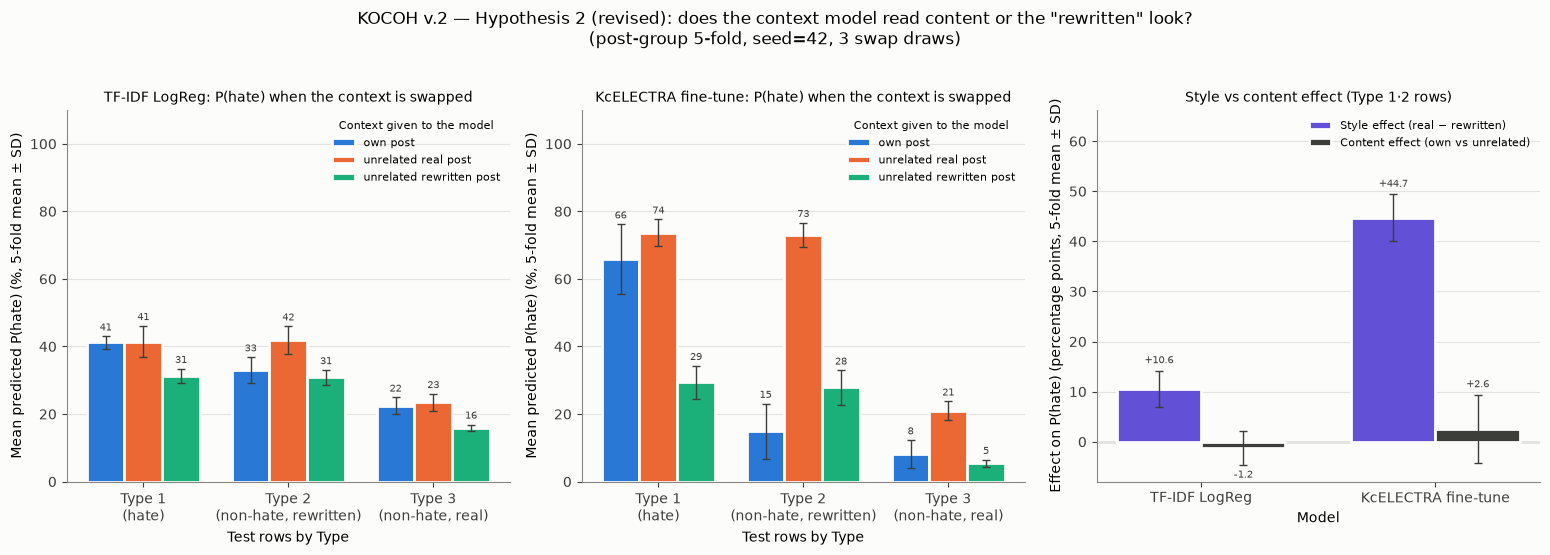

In [11]:
import matplotlib.pyplot as plt

SURFACE, INK, MUTED, GRID = '#fcfcfb', '#3d3d3a', '#898781', '#e4e3dd'
VAR_COLOR = {'own': '#2a78d6', 'real_other': '#eb6834', 'rew_other': '#1baf7a'}
VAR_LABEL = {'own': 'own post', 'real_other': 'unrelated real post', 'rew_other': 'unrelated rewritten post'}
EFF_COLOR = {'style': '#6250d6', 'content': '#3d3d3a'}
EFF_LABEL = {'style': 'Style effect (real − rewritten)', 'content': 'Content effect (own vs unrelated)'}
SHORT = {'TF-IDF LogReg': 'TF-IDF LogReg', 'KcELECTRA-base-v2022 (finetune)': 'KcELECTRA fine-tune',
         'klue-roberta-base (finetune)': 'KLUE-RoBERTa fine-tune'}


def style_ax(ax):
    ax.set_facecolor(SURFACE)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color(MUTED)
    ax.tick_params(colors=INK)
    ax.grid(axis='y', color=GRID, linewidth=0.8, zorder=0)


def bars(ax, xs, mu, sd, color, label, fmt):
    ax.bar(xs, mu, w, yerr=sd, color=color, label=label, edgecolor=SURFACE, linewidth=2,
           error_kw=dict(ecolor=INK, elinewidth=1, capsize=3), zorder=2)
    for xi, v, e in zip(xs, mu, sd):
        y = v + e + 1 if v >= 0 else v - e - 1
        ax.text(xi, y, fmt.format(v), ha='center', va='bottom' if v >= 0 else 'top', fontsize=7.5, color=INK)


n = len(MODELS)
fig, axes = plt.subplots(1, n + 1, figsize=(5.2 * (n + 1), 5.4), facecolor=SURFACE)
stat = by_type.groupby(level=['model', 'Type']).agg(['mean', 'std'])

# (a~) 모델별: Type × 입력별 평균 P(혐오)
w = 0.26
for ax, m in zip(axes[:n], MODELS):
    style_ax(ax)
    x = np.arange(3)
    for i, v in enumerate(VARIANTS):
        mu = [stat.loc[(m, t), (v, 'mean')] for t in (1, 2, 3)]
        sd = [stat.loc[(m, t), (v, 'std')] for t in (1, 2, 3)]
        bars(ax, x + (i - 1) * w, mu, sd, VAR_COLOR[v], VAR_LABEL[v], '{:.0f}')
    ax.set_xticks(x)
    ax.set_xticklabels(['Type 1\n(hate)', 'Type 2\n(non-hate, rewritten)', 'Type 3\n(non-hate, real)'])
    ax.set_ylim(0, 110)
    ax.set_xlabel('Test rows by Type')
    ax.set_ylabel('Mean predicted P(hate) (%, 5-fold mean ± SD)')
    ax.set_title(f"{SHORT.get(m, m)}: P(hate) when the context is swapped", fontsize=10)
    ax.legend(title='Context given to the model', frameon=False, loc='upper right', fontsize=8, title_fontsize=8)

# 마지막: 효과 크기 비교 (Type 1·2)
ax = axes[-1]
style_ax(ax)
ax.axhline(0, color=MUTED, linewidth=1, zorder=1)
x = np.arange(n)
w = 0.36
e12 = effects[effects['scope'] == 'Type 1·2'].groupby('model')[['style', 'content']].agg(['mean', 'std'])
for i, k in enumerate(['style', 'content']):
    bars(ax, x + (i - 0.5) * w, [e12.loc[m, (k, 'mean')] for m in MODELS], [e12.loc[m, (k, 'std')] for m in MODELS],
         EFF_COLOR[k], EFF_LABEL[k], '{:+.1f}')
ax.set_xticks(x)
ax.set_xticklabels([SHORT.get(m, m) for m in MODELS])
lo = min(0, float((e12.xs('mean', axis=1, level=1) - e12.xs('std', axis=1, level=1)).min().min()))
hi = float((e12.xs('mean', axis=1, level=1) + e12.xs('std', axis=1, level=1)).max().max())
ax.set_ylim(lo * 1.3 - 2, hi * 1.3 + 2)
ax.set_xlabel('Model')
ax.set_ylabel('Effect on P(hate) (percentage points, 5-fold mean ± SD)')
ax.set_title('Style vs content effect (Type 1·2 rows)', fontsize=10)
ax.legend(frameon=False, loc='upper right', fontsize=8)

fig.suptitle(f'KOCOH v.2 — Hypothesis 2 (revised): does the context model read content or the "rewritten" look?\n'
             f'(post-group 5-fold, seed={SEED}, {N_DRAWS} swap draws)', y=1.02)
fig.tight_layout()
if FIG_PATH.exists():
    print(f"알림: {FIG_PATH.relative_to(PROJECT_ROOT)} 이(가) 이미 있어 덮어씁니다.")
fig.savefig(FIG_PATH, dpi=150, bbox_inches='tight')
print(f"저장: {FIG_PATH.relative_to(PROJECT_ROOT)}")
plt.show()

### 5-1. 조건 A~F 그림 — 노션 결과 표와 같은 수치

KcELECTRA, 혐오 판정 비율(확률 > 0.5), Type 1·2. 4-1절 표의 값을 그대로 그린다.
- B(혐오 댓글 + 남의 새로 쓴 글)가 낮은 것은 정상이다. 무관한 글이 붙으면 비혐오가 되는 게 자연스럽다.
- 봐야 할 것은 똑같이 무관한 글인데 실제 글이면 C·F처럼 높게 나온다는 점이다 (괄호 = 티 효과).

알림: figures/project_h2_af_hate_rate.png 이(가) 이미 있어 덮어씁니다.


저장: figures/project_h2_af_hate_rate.png


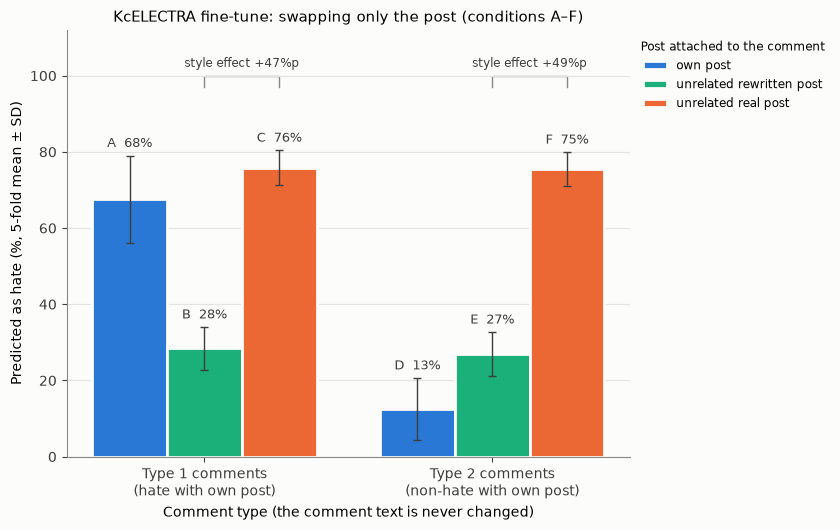

In [12]:
AF_PATH = PROJECT_ROOT / 'figures' / 'project_h2_af_hate_rate.png'
AF_MODEL = f'{PLM_MODELS[0]} (finetune)'
AF_ORDER = ['own', 'rew_other', 'real_other']   # A·B·C / D·E·F 순서
AF_LABEL = {'own': 'own post', 'rew_other': 'unrelated rewritten post', 'real_other': 'unrelated real post'}

hr = per_fold_tv.loc[AF_MODEL, 'hate'].unstack('variant')   # (fold, Type) × variant, 단위 %
fig, ax = plt.subplots(figsize=(8.5, 5.4), facecolor=SURFACE)
style_ax(ax)
w = 0.26
for j, t in enumerate((1, 2)):
    sub = hr.xs(t, level='Type')
    for i, v in enumerate(AF_ORDER):
        x = j + (i - 1) * w
        mu, sd = sub[v].mean(), sub[v].std(ddof=1)
        ax.bar(x, mu, w, yerr=sd, color=VAR_COLOR[v], label=AF_LABEL[v] if j == 0 else None, edgecolor=SURFACE,
               linewidth=2, error_kw=dict(ecolor=INK, elinewidth=1, capsize=3), zorder=2)
        ax.text(x, mu + sd + 1.5, f"{LETTER[(t, v)]}  {mu:.0f}%", ha='center', va='bottom', fontsize=9, color=INK)
    # 티 효과: 남의 실제 글 − 남의 새로 쓴 글
    gap = (sub['real_other'] - sub['rew_other']).mean()
    xb, xc, top = j, j + w, 100
    ax.plot([xb, xb, xc, xc], [top - 3, top, top, top - 3], color=MUTED, linewidth=1, zorder=1)
    ax.text((xb + xc) / 2, top + 1.5, f"style effect +{gap:.0f}%p", ha='center', va='bottom', fontsize=8.5, color=INK)
ax.set_xticks([0, 1])
ax.set_xticklabels(['Type 1 comments\n(hate with own post)', 'Type 2 comments\n(non-hate with own post)'])
ax.set_ylim(0, 112)
ax.set_xlabel('Comment type (the comment text is never changed)')
ax.set_ylabel('Predicted as hate (%, 5-fold mean ± SD)')
ax.set_title(f'{SHORT.get(AF_MODEL, AF_MODEL)}: swapping only the post (conditions A–F)', fontsize=11)
ax.legend(title='Post attached to the comment', frameon=False, loc='upper left', bbox_to_anchor=(1.0, 1.0), fontsize=8.5, title_fontsize=8.5)
fig.tight_layout()
if AF_PATH.exists():
    print(f"알림: {AF_PATH.relative_to(PROJECT_ROOT)} 이(가) 이미 있어 덮어씁니다.")
fig.savefig(AF_PATH, dpi=150, bbox_inches='tight')
print(f"저장: {AF_PATH.relative_to(PROJECT_ROOT)}")
plt.show()

In [13]:
# 실험로그 요약 (CLAUDE.md 형식: 실험 이름 / 설정 / 지표 / 결과 파일)
config = (f"KOCOH v2 3,000행, post_group 5-fold StratifiedGroupKFold(seed={SEED}); Context+Comment 모델(중간보고 설정)을 fold별 학습 후 "
          f"test Context만 교체(own / 다른 post_group의 실제 글 / 고쳐 쓴 글, {N_DRAWS}회 추출 평균, seed={SEED}); "
          f"판정=평균 부호+4/5 fold+대응 t p<0.05, Type 1·2 기준")
parts_log = []
for m in MODELS:
    for k, name in [('겉모습 효과', 'style_pp'), ('내용 효과', 'content_pp')]:
        parts_log.append(f"{name}[{m}]={judge.loc[(m, 'Type 1·2', k), '평균 (%p)']} ({judge.loc[(m, 'Type 1·2', k), '판정']})")
    parts_log.append(f"가설2수정안[{m}]={concl.loc[m, '가설 2 (수정안)']}")
files = ', '.join(str(p.relative_to(PROJECT_ROOT)) for p in (FIG_PATH, AF_PATH))
print("실험 이름 / 설정 / 지표 / 결과 파일")
print(f"팀프로젝트_가설2 / {config} / {'; '.join(parts_log)} / {files}")

실험 이름 / 설정 / 지표 / 결과 파일
팀프로젝트_가설2 / KOCOH v2 3,000행, post_group 5-fold StratifiedGroupKFold(seed=42); Context+Comment 모델(중간보고 설정)을 fold별 학습 후 test Context만 교체(own / 다른 post_group의 실제 글 / 고쳐 쓴 글, 3회 추출 평균, seed=42); 판정=평균 부호+4/5 fold+대응 t p<0.05, Type 1·2 기준 / style_pp[TF-IDF LogReg]=+10.6 ± 3.6 (유의 (+)); content_pp[TF-IDF LogReg]=-1.2 ± 3.4 (판단 보류); 가설2수정안[TF-IDF LogReg]=지지 — 겉모습에 반응; style_pp[KcELECTRA-base-v2022 (finetune)]=+44.7 ± 4.7 (유의 (+)); content_pp[KcELECTRA-base-v2022 (finetune)]=+2.6 ± 6.8 (판단 보류); 가설2수정안[KcELECTRA-base-v2022 (finetune)]=지지 — 겉모습에 반응 / figures/project_h2_style_vs_content.png, figures/project_h2_af_hate_rate.png


---
## 6. 결론

**판정 (사전 기준, Type 1·2 합산) — KcELECTRA fine-tuning: 가설 2(수정안) 지지**
- 겉모습(티) 효과 **+44.7 ± 4.7%p** (5/5 fold, p < 0.001) — 유의
- 내용 효과 **+2.6 ± 6.8%p** (3/5 fold, p = 0.446) — 판단 보류
- 재현 확인: `own` 입력의 macro-F1 0.809 (중간보고 0.809, fold별 차이 최대 0.012)

> Type별로 나누면(4-1절) Type 1은 지지, Type 2는 부분 지지(내용 효과 +12.9%p도 유의)다. 합친 내용 효과 +2.6%p는 Type 1(−7.8)과 Type 2(+12.9)가 상쇄된 값이므로 "내용 효과 없음"으로 읽으면 안 된다.

**무엇을 보여주나 (4-1절, 혐오 판정 비율)**

| 댓글 \ 붙인 글 | 원래 글 | 남의 새로 쓴 글 | 남의 실제 글 |
|---|---|---|---|
| Type 1 (혐오) | A 67.6% | B 28.4% | C 75.8% |
| Type 2 (비혐오) | D 12.5% | E 26.8% | F 75.4% |

- B가 낮은 것은 정상이다. 무관한 글이 붙으면 비혐오가 되는 게 자연스럽다.
- 문제는 똑같이 무관한 글인데 **실제 글이면 C·F처럼 약 75%가 혐오로 판정**된다는 점이다. 원래 글(A 67.6%)보다도 높다. 관계를 읽어 혐오를 잡는다는 증거는 보이지 않는다.
- 내용을 전혀 안 쓰는 것은 아니다. Type 2는 원래 글이 무관한 새로 쓴 글보다 비혐오 쪽으로 더 밀었고(내용 효과 유의), Type 3도 내용 효과 +12.8 ± 5.8%p(5/5, p = 0.008)가 유의했다. 그러나 티 효과(약 45~49%p)보다 훨씬 작다.
- TF-IDF(관계를 원리적으로 못 읽는 모델)도 같은 방향(티 효과 혐오 판정 비율 기준 약 +15%p, 내용 효과 0 근처)이다.

**의미**: 중간보고의 맥락 이득(KcELECTRA macro-F1 0.672 → 0.809)은 상당 부분 "새로 쓴 글이면 비혐오"라는 데이터 구성 단서에서 왔을 가능성이 크다. 보고서에는 한계로 분명히 적는다.

**해석할 때 주의할 점 (한계)**
- 글을 바꾸면 정답도 바뀔 수 있다. 바꿔 끼운 입력은 정답을 모르는 입력이고, 티 효과는 "무관한 글을 붙이면 대부분 비혐오"라는 가정에 기댄다 (사람 판정으로 확인하지 않음).
- 남의 글은 다른 게시글 묶음의 글이라 **주제**도 바뀐다. 1-2절 상위 n-gram을 보면 실제 글 쪽은 "여성·남성·사건", 새로 쓴 글 쪽은 "맛·있다·물었다·지역"이다. 그래서 '티'는 문체보다 "혐오 대상·사건이 들어간 주제인가"에 가까울 수 있다.
- 예측은 파일로 저장하지 않으므로, 노트북을 다시 실행하면 처음부터 학습하고 PLM 수치가 소수점 단위로 조금 달라질 수 있다 (MPS 비결정성).
- PLM은 KcELECTRA만 돌렸다 (KLUE-RoBERTa는 `PLM_MODELS` 에 추가하면 같은 방식으로 확인 가능).
